In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python Data Science Environment Ready!")

Python Data Science Environment Ready!


In [4]:
data = {
    'Product': ['Laptop', 'Mobile', 'Keyboard', 'Mouse', 'Laptop'],
    'City': ['Pune', 'Mumbai', 'Pune', 'Nashik', 'Pune'],
    'Quantity': [2, 5, 10, 8, 1],
    'Price': [50000, 15000, 500, 700, 50000]
}

df = pd.DataFrame(data)

df

,Product,City,Quantity,Price
0,Laptop,Pune,2,50000
1,Mobile,Mumbai,5,15000
2,Keyboard,Pune,10,500
3,Mouse,Nashik,8,700
4,Laptop,Pune,1,50000


In [5]:
df.head()

,Product,City,Quantity,Price
0,Laptop,Pune,2,50000
1,Mobile,Mumbai,5,15000
2,Keyboard,Pune,10,500
3,Mouse,Nashik,8,700
4,Laptop,Pune,1,50000


In [6]:
df.shape

(5, 4)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Product   5 non-null      object
 1   City      5 non-null      object
 2   Quantity  5 non-null      int64 
 3   Price     5 non-null      int64 
dtypes: int64(2), object(2)
memory usage: 292.0+ bytes


In [8]:
df.describe()

,Quantity,Price
count,5.000000,5.000000
mean,5.200000,23240.000000
std,3.834058,25125.942768
min,1.000000,500.000000
25%,2.000000,700.000000
50%,5.000000,15000.000000
75%,8.000000,50000.000000
max,10.000000,50000.000000


In [9]:
df['Revenue'] = df['Quantity'] * df['Price']

df

,Product,City,Quantity,Price,Revenue
0,Laptop,Pune,2,50000,100000
1,Mobile,Mumbai,5,15000,75000
2,Keyboard,Pune,10,500,5000
3,Mouse,Nashik,8,700,5600
4,Laptop,Pune,1,50000,50000


In [10]:
total_sales = df['Revenue'].sum()

print("Total Sales:", total_sales)

Total Sales: 235600


In [11]:
df['Quantity'].sum()

np.int64(26)

In [12]:
df['Revenue'].mean()

np.float64(47120.0)

In [13]:
df['Revenue'].max()

100000

In [14]:
product_sales = df.groupby('Product')['Revenue'].sum()

product_sales

Product
Keyboard      5000
Laptop      150000
Mobile       75000
Mouse         5600
Name: Revenue, dtype: int64

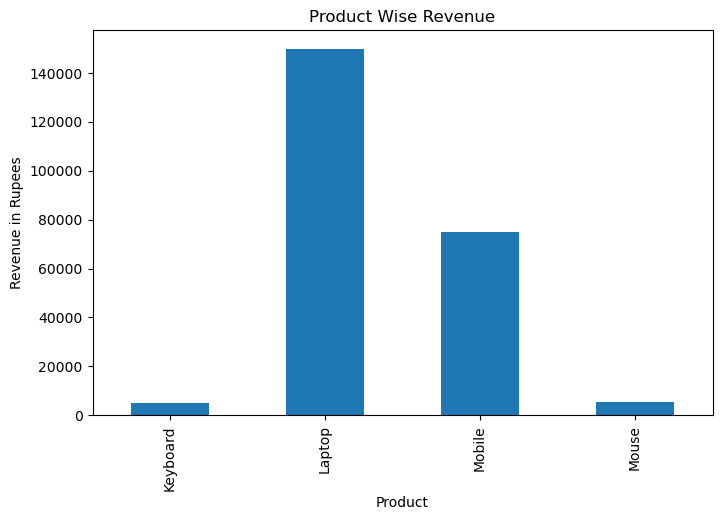

In [15]:
product_sales.plot(kind='bar', figsize=(8,5))

plt.title('Product Wise Revenue')
plt.xlabel('Product')
plt.ylabel('Revenue in Rupees')
plt.show()

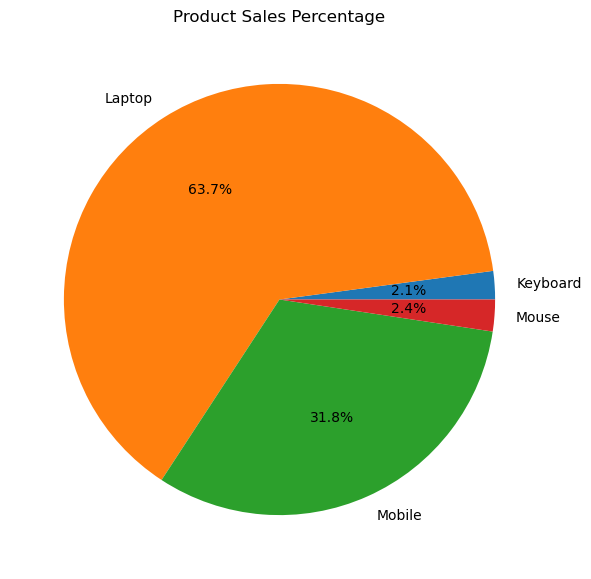

In [16]:
product_sales.plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(7,7)
)

plt.title('Product Sales Percentage')
plt.ylabel('')
plt.show()

In [17]:
sales_percentage = (product_sales / total_sales) * 100

print(sales_percentage.round(2))

Product
Keyboard     2.12
Laptop      63.67
Mobile      31.83
Mouse        2.38
Name: Revenue, dtype: float64


In [18]:
city_sales = df.groupby('City')['Revenue'].sum()

print(city_sales)

City
Mumbai     75000
Nashik      5600
Pune      155000
Name: Revenue, dtype: int64


In [19]:
best_city = city_sales.idxmax()

print("Best Sales City:", best_city)

Best Sales City: Pune


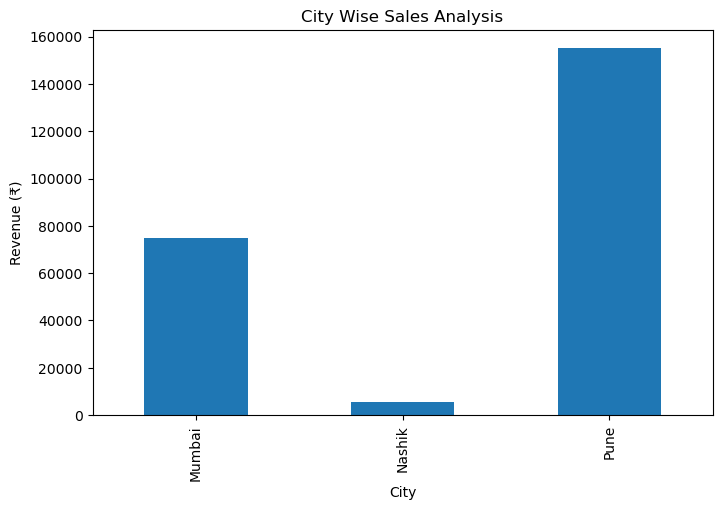

In [20]:
city_sales.plot(
    kind='bar',
    figsize=(8,5),
    title='City Wise Sales Analysis'
)

plt.xlabel('City')
plt.ylabel('Revenue (₹)')
plt.show()

In [22]:
df['Date'] = pd.to_datetime([
    '2026-01-05',
    '2026-01-10',
    '2026-02-15',
    '2026-02-20',
    '2026-03-05'
])

df

,Product,City,Quantity,Price,Revenue,Date
0,Laptop,Pune,2,50000,100000,2026-01-05
1,Mobile,Mumbai,5,15000,75000,2026-01-10
2,Keyboard,Pune,10,500,5000,2026-02-15
3,Mouse,Nashik,8,700,5600,2026-02-20
4,Laptop,Pune,1,50000,50000,2026-03-05


In [23]:
df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Revenue'].sum()

print(monthly_sales)

Month
2026-01    175000
2026-02     10600
2026-03     50000
Freq: M, Name: Revenue, dtype: int64


In [24]:
df['Month'] = df['Date'].dt.to_period('M')

monthly_sales = df.groupby('Month')['Revenue'].sum()

print(monthly_sales)

Month
2026-01    175000
2026-02     10600
2026-03     50000
Freq: M, Name: Revenue, dtype: int64


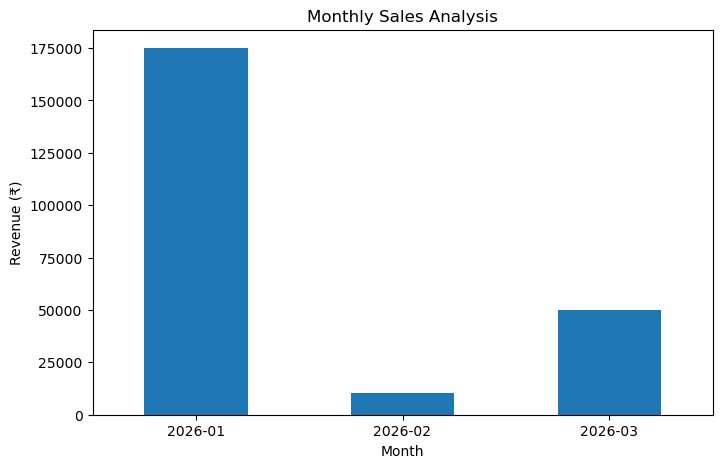

In [25]:
monthly_sales.plot(kind='bar', figsize=(8,5))

plt.title('Monthly Sales Analysis')
plt.xlabel('Month')
plt.ylabel('Revenue (₹)')
plt.xticks(rotation=0)

plt.show()

In [26]:
best_city = city_sales.idxmax()
highest_sales = city_sales.max()

print("Best Performing City:", best_city)
print("Highest Sales: ₹", highest_sales)

Best Performing City: Pune
Highest Sales: ₹ 155000


In [27]:
print("===== SALES REPORT =====")

print("Total Revenue: ₹", df['Revenue'].sum())

print("Total Quantity:", df['Quantity'].sum())

print("Best Selling Product:",
      df.groupby('Product')['Revenue'].sum().idxmax())

print("Best Performing City:",
      df.groupby('City')['Revenue'].sum().idxmax())

print("Best Sales Month:",
      monthly_sales.idxmax())

===== SALES REPORT =====
Total Revenue: ₹ 235600
Total Quantity: 26
Best Selling Product: Laptop
Best Performing City: Pune
Best Sales Month: 2026-01


In [28]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:")
print(df.duplicated().sum())

print("Dataset Shape:")
print(df.shape)

Missing Values:
Product     0
City        0
Quantity    0
Price       0
Revenue     0
Date        0
Month       0
dtype: int64
Duplicate Rows:
0
Dataset Shape:
(5, 7)


In [29]:
df.describe()

,Quantity,Price,Revenue,Date
count,5.000000,5.000000,5.000000,5
mean,5.200000,23240.000000,47120.000000,2026-02-04 04:48:00
min,1.000000,500.000000,5000.000000,2026-01-05 00:00:00
25%,2.000000,700.000000,5600.000000,2026-01-10 00:00:00
50%,5.000000,15000.000000,50000.000000,2026-02-15 00:00:00
75%,8.000000,50000.000000,75000.000000,2026-02-20 00:00:00
max,10.000000,50000.000000,100000.000000,2026-03-05 00:00:00
std,3.834058,25125.942768,42071.035167,NaN


In [30]:
correlation = df[['Quantity', 'Price', 'Revenue']].corr()

print(correlation)

          Quantity     Price   Revenue
Quantity  1.000000 -0.956668 -0.783185
Price    -0.956668  1.000000  0.746418
Revenue  -0.783185  0.746418  1.000000


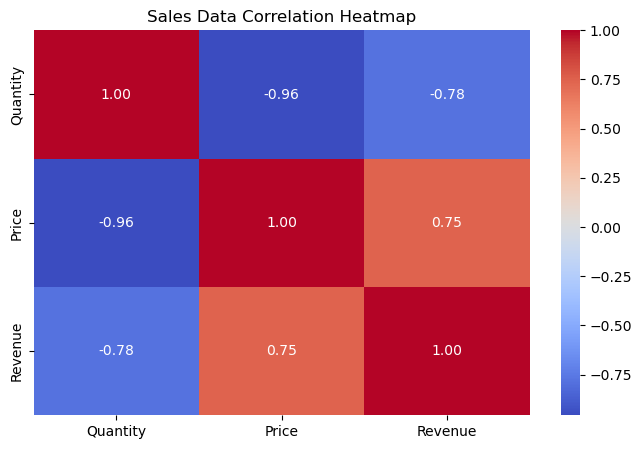

In [31]:
plt.figure(figsize=(8,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Sales Data Correlation Heatmap')
plt.show()